# Install & imports

In [12]:
!pip install -q PyWavelets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import skew, kurtosis
from scipy.signal import welch, stft
import pywt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

print('Imports OK')

Imports OK


# Reconnect paths

In [13]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/PD_EEG_Thesis_Features_v2')
SEG_DIR      = PROJECT_ROOT / 'data' / 'segments'
FEAT_DIR     = PROJECT_ROOT / 'data' / 'features'
CSV_DIR      = PROJECT_ROOT / 'data' / 'feature_csv'
FIG_DIR      = PROJECT_ROOT / 'figures'
FEAT_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

d = np.load(str(SEG_DIR / 'segments_all.npz'))
X, y, subjects = d['X'], d['y'], d['subjects']
print(f'Loaded: {X.shape}  PD={int(y.sum())}  Control={int((y==0).sum())}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded: (3915, 60, 3000)  PD=2549  Control=1366


# Feature extraction parameters

In [14]:
FS             = 500
N_TIMESTEPS    = 6        # non-overlapping 1s windows — proven design
SUBWIN_SAMPLES = 500

BANDS = {'delta': (0.5,4), 'theta': (4,8), 'alpha': (8,13), 'beta': (13,30), 'gamma': (30,45)}
WAVELET, WAVELET_LEVEL = 'db4', 3

# Domain quotas — literal to supervisor's instruction
N_TIME_FINAL, N_FREQ_FINAL, N_TF_FINAL = 8, 8, 4
CORR_DEDUP_THRESHOLD = 0.85   # candidates correlating above this are treated as redundant

print(f'Sub-window: {N_TIMESTEPS} × {SUBWIN_SAMPLES} samples (1s each, non-overlapping)')
print(f'Target: {N_TIME_FINAL} time + {N_FREQ_FINAL} freq + {N_TF_FINAL} time-freq = {N_TIME_FINAL+N_FREQ_FINAL+N_TF_FINAL} total')

Sub-window: 6 × 500 samples (1s each, non-overlapping)
Target: 8 time + 8 freq + 4 time-freq = 20 total


# Candidate feature functions (time / frequency / time-frequency domains)

In [15]:
def time_domain_candidates(sw):
    """sw: (n_ch, 500) -> dict of {name: (n_ch,) array}. 12 candidates."""
    std  = sw.std(axis=1)

    # NaN-safe skew/kurtosis: zero-variance segments are mathematically
    # undefined for these; default to 0 rather than letting NaN propagate
    # and poison the entire downstream Cohen's d calculation.
    zero_var_mask = std < 1e-8
    sk = np.where(zero_var_mask, 0.0, skew(sw, axis=1))
    ku = np.where(zero_var_mask, 0.0, kurtosis(sw, axis=1))
    sk = np.nan_to_num(sk, nan=0.0)
    ku = np.nan_to_num(ku, nan=0.0)

    rms  = np.sqrt(np.mean(sw**2, axis=1))
    zcr  = np.mean(np.diff(np.sign(sw), axis=1) != 0, axis=1)
    line_length = np.sum(np.abs(np.diff(sw, axis=1)), axis=1)
    ptp  = np.ptp(sw, axis=1)
    mav  = np.mean(np.abs(sw), axis=1)

    d1 = np.diff(sw, axis=1); d2 = np.diff(d1, axis=1)
    var0, var1, var2 = np.var(sw, axis=1), np.var(d1, axis=1), np.var(d2, axis=1)
    mobility   = np.sqrt(var1 / (var0 + 1e-12))
    complexity = np.sqrt(var2 / (var1 + 1e-12)) / (mobility + 1e-12)
    activity   = var0

    ssc = np.mean(np.diff(np.sign(np.diff(sw, axis=1)), axis=1) != 0, axis=1)

    return {
        'std': std, 'skewness': sk, 'kurtosis': ku, 'rms': rms,
        'zero_crossing_rate': zcr, 'line_length': line_length, 'peak_to_peak': ptp,
        'mean_abs_value': mav, 'hjorth_mobility': mobility, 'hjorth_complexity': complexity,
        'hjorth_activity': activity, 'slope_sign_changes': ssc,
    }


def freq_domain_candidates(sw, fs=FS):
    """Unchanged — this domain had no issues."""
    freqs, psd = welch(sw, fs=fs, nperseg=min(250, sw.shape[1]), axis=1)
    total_power = np.sum(psd, axis=1) + 1e-12

    band_powers = {}
    for name, (lo, hi) in BANDS.items():
        mask = (freqs >= lo) & (freqs < hi)
        band_powers[f'{name}_power'] = np.sum(psd[:, mask], axis=1) / total_power

    theta_beta = np.clip(band_powers['theta_power'] / (band_powers['beta_power'] + 1e-6), 0, 20)
    alpha_beta = np.clip(band_powers['alpha_power'] / (band_powers['beta_power'] + 1e-6), 0, 20)
    delta_theta = np.clip(band_powers['delta_power'] / (band_powers['theta_power'] + 1e-6), 0, 20)

    peak_freq = freqs[np.argmax(psd, axis=1)]
    cumsum = np.cumsum(psd, axis=1) / total_power[:, None]
    sef95 = np.array([freqs[np.searchsorted(cumsum[i], 0.95)] if np.any(cumsum[i] >= 0.95) else freqs[-1]
                      for i in range(sw.shape[0])])
    psd_norm = psd / total_power[:, None]
    spec_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12), axis=1) / np.log2(psd.shape[1])
    spec_centroid = np.sum(freqs[None, :] * psd, axis=1) / total_power

    out = dict(band_powers)
    out.update({
        'theta_beta_ratio': theta_beta, 'alpha_beta_ratio': alpha_beta, 'delta_theta_ratio': delta_theta,
        'peak_frequency': peak_freq, 'spectral_edge_95': sef95,
        'spectral_entropy': spec_entropy, 'spectral_centroid': spec_centroid,
    })
    return out


def time_freq_candidates(sw, wavelet=WAVELET, level=WAVELET_LEVEL, fs=FS):
    """sw: (n_ch, 500) -> dict. EXPANDED to 11 candidates — the original 6
    wavelet-sub-band-heavy pool couldn't fill 4 independent slots after
    deduplication (sub-band energies are mechanically correlated with each
    other). Added Hilbert-transform and Teager-Kaiser features, which are
    mathematically distinct from wavelet/STFT decomposition."""
    from scipy.signal import hilbert

    n_ch = sw.shape[0]
    energies_1, energies_2, energies_3, energies_4 = [], [], [], []
    wav_entropy, stft_var = [], []
    hilbert_amp, hilbert_freq, teager_energy = [], [], []
    stft_low_power, stft_high_power = [], []

    for ch in range(n_ch):
        coeffs = pywt.wavedec(sw[ch], wavelet, level=level)
        e = np.array([np.sum(c**2) for c in coeffs])
        e = e / (e.sum() + 1e-12)
        e = np.pad(e, (0, max(0, 4-len(e))))[:4]
        energies_1.append(e[0]); energies_2.append(e[1]); energies_3.append(e[2]); energies_4.append(e[3])
        wav_entropy.append(-np.sum(e * np.log2(e + 1e-12)))

        f, t, Zxx = stft(sw[ch], fs=fs, nperseg=min(128, len(sw[ch])))
        mag = np.abs(Zxx); mag_sum = np.sum(mag, axis=0)
        eps = mag_sum.max() * 1e-6 + 1e-10
        centroid = np.sum(f[:, None] * mag, axis=0) / (mag_sum + eps)
        stft_var.append(np.var(centroid))

        # Band-specific STFT power (distinct info from a single centroid summary stat)
        total_mag = np.sum(mag) + 1e-12
        low_mask  = f < 13   # delta+theta+alpha
        high_mask = f >= 13  # beta+gamma
        stft_low_power.append(np.sum(mag[low_mask, :]) / total_mag)
        stft_high_power.append(np.sum(mag[high_mask, :]) / total_mag)

        # Hilbert transform — instantaneous amplitude & frequency (genuinely
        # different mathematical basis than wavelet/STFT decomposition)
        analytic = hilbert(sw[ch])
        envelope = np.abs(analytic)
        hilbert_amp.append(envelope.mean())

        phase = np.unwrap(np.angle(analytic))
        inst_freq = np.diff(phase) / (2.0 * np.pi) * fs
        hilbert_freq.append(np.mean(np.abs(inst_freq)))

        # Teager-Kaiser Energy Operator — captures instantaneous energy
        # incorporating both amplitude and frequency jointly
        x = sw[ch]
        tkeo = x[1:-1]**2 - x[:-2]*x[2:]
        teager_energy.append(np.mean(tkeo))

    return {
        'wavelet_energy_1': np.array(energies_1), 'wavelet_energy_2': np.array(energies_2),
        'wavelet_energy_3': np.array(energies_3), 'wavelet_energy_4': np.array(energies_4),
        'wavelet_entropy': np.array(wav_entropy), 'stft_centroid_variance': np.array(stft_var),
        'stft_low_band_power': np.array(stft_low_power), 'stft_high_band_power': np.array(stft_high_power),
        'hilbert_inst_amplitude': np.array(hilbert_amp), 'hilbert_inst_frequency': np.array(hilbert_freq),
        'teager_energy': np.array(teager_energy),
    }

print('Candidate functions updated: NaN-safe time domain, expanded time-frequency pool (6 → 11 candidates).')

Candidate functions updated: NaN-safe time domain, expanded time-frequency pool (6 → 11 candidates).


# Z-score + extract all candidates for every window/timestep/channel

In [16]:
def zscore_window(window):
    std = window.std()
    if std < 1e-8: std = 1e-8
    return (window - window.mean()) / std

# Collect candidate names once
sample_sw = zscore_window(X[0])[:, :SUBWIN_SAMPLES]
time_names = list(time_domain_candidates(sample_sw).keys())
freq_names = list(freq_domain_candidates(sample_sw).keys())
tf_names   = list(time_freq_candidates(sample_sw).keys())
ALL_CANDIDATE_NAMES = time_names + freq_names + tf_names
N_CANDIDATES = len(ALL_CANDIDATE_NAMES)
print(f'Total candidates: {N_CANDIDATES}  ({len(time_names)} time, {len(freq_names)} freq, {len(tf_names)} time-freq)')

n_samples, n_ch, _ = X.shape
all_features = np.zeros((n_samples, N_TIMESTEPS, n_ch, N_CANDIDATES), dtype=np.float32)

for i in range(n_samples):
    w = zscore_window(X[i])
    for t in range(N_TIMESTEPS):
        sw = w[:, t*SUBWIN_SAMPLES:(t+1)*SUBWIN_SAMPLES]
        t_feats = time_domain_candidates(sw)
        f_feats = freq_domain_candidates(sw)
        tf_feats = time_freq_candidates(sw)
        combined = {**t_feats, **f_feats, **tf_feats}
        all_features[i, t] = np.stack([combined[name] for name in ALL_CANDIDATE_NAMES], axis=1)
    if (i+1) % 500 == 0:
        print(f'  Processed {i+1}/{n_samples}')

# Clip outliers, same safeguard as before
for f_idx in range(N_CANDIDATES):
    p1, p99 = np.percentile(all_features[:,:,:,f_idx], [1, 99])
    all_features[:,:,:,f_idx] = np.clip(all_features[:,:,:,f_idx], p1, p99)

print('\nCandidate extraction + clipping complete.')

Total candidates: 35  (12 time, 12 freq, 11 time-freq)
  Processed 500/3915
  Processed 1000/3915
  Processed 1500/3915
  Processed 2000/3915
  Processed 2500/3915
  Processed 3000/3915
  Processed 3500/3915

Candidate extraction + clipping complete.


# Feature selection — Cohen's d ranking, quota-respecting, correlation deduplication

In [17]:
MIN_EFFECT_SIZE = 0.15
CORR_DEDUP_THRESHOLD = 0.90

def cohens_d(a, b):
    n1,n2 = len(a),len(b)
    v1,v2 = a.var(ddof=1), b.var(ddof=1)
    pooled = np.sqrt(((n1-1)*v1+(n2-1)*v2)/(n1+n2-2))
    return 0.0 if pooled < 1e-12 else (a.mean()-b.mean())/pooled

def rank_domain(names, all_features, y, name_offset):
    scores = []
    for i, name in enumerate(names):
        idx = name_offset + i
        vals = all_features[:,:,:,idx].ravel()
        labels = np.repeat(y, all_features.shape[1]*all_features.shape[2])
        d = cohens_d(vals[labels==1], vals[labels==0])
        scores.append({'feature': name, 'index': idx, 'cohens_d': d, 'abs_d': abs(d)})
    df = pd.DataFrame(scores)
    df = df[df['cohens_d'].notna()].copy()
    return df.sort_values('abs_d', ascending=False).reset_index(drop=True)

def select_with_dedup(ranked_df, all_features, n_target, corr_threshold=CORR_DEDUP_THRESHOLD,
                      min_effect=MIN_EFFECT_SIZE, domain_name=''):
    usable_df = ranked_df[ranked_df['abs_d'] >= min_effect].copy()
    selected_idx = []
    flat_per_feature = {row['index']: all_features[:,:,:,row['index']].ravel() for _, row in usable_df.iterrows()}
    for _, row in usable_df.iterrows():
        if len(selected_idx) >= n_target:
            break
        candidate_vals = flat_per_feature[row['index']]
        redundant = any(abs(np.corrcoef(candidate_vals, flat_per_feature[s])[0,1]) > corr_threshold
                        for s in selected_idx)
        if not redundant:
            selected_idx.append(row['index'])
    return selected_idx

time_ranked = rank_domain(time_names, all_features, y, 0)
freq_ranked = rank_domain(freq_names, all_features, y, len(time_names))
tf_ranked   = rank_domain(tf_names, all_features, y, len(time_names)+len(freq_names))

print('=== Time domain ranking ===\n', time_ranked[['feature','cohens_d']].to_string(index=False))
print('\n=== Frequency domain ranking ===\n', freq_ranked[['feature','cohens_d']].to_string(index=False))
print('\n=== Time-frequency ranking ===\n', tf_ranked[['feature','cohens_d']].to_string(index=False))

time_selected = select_with_dedup(time_ranked, all_features, N_TIME_FINAL, domain_name='Time')
freq_selected = select_with_dedup(freq_ranked, all_features, N_FREQ_FINAL, domain_name='Frequency')
tf_selected   = select_with_dedup(tf_ranked, all_features, N_TF_FINAL, domain_name='Time-Frequency')

selected_indices = time_selected + freq_selected + tf_selected
selected_names   = [ALL_CANDIDATE_NAMES[i] for i in selected_indices]

print(f'\n\n=== FINAL SELECTED {len(selected_indices)} FEATURES ===')
print(f'Time ({len(time_selected)}): {[ALL_CANDIDATE_NAMES[i] for i in time_selected]}')
print(f'Freq ({len(freq_selected)}): {[ALL_CANDIDATE_NAMES[i] for i in freq_selected]}')
print(f'Time-Freq ({len(tf_selected)}): {[ALL_CANDIDATE_NAMES[i] for i in tf_selected]}')

=== Time domain ranking ===
            feature  cohens_d
 hjorth_complexity  0.423097
zero_crossing_rate -0.387230
   hjorth_mobility -0.381708
       line_length -0.302783
          kurtosis -0.155775
      peak_to_peak -0.154712
slope_sign_changes -0.092954
    mean_abs_value  0.034006
               rms  0.014968
   hjorth_activity -0.009596
          skewness -0.006477
               std -0.004082

=== Frequency domain ranking ===
           feature  cohens_d
       beta_power -0.527302
 theta_beta_ratio  0.486500
      theta_power  0.482456
 spectral_entropy -0.411973
 alpha_beta_ratio  0.406794
spectral_centroid -0.379035
 spectral_edge_95 -0.320582
      gamma_power -0.256521
delta_theta_ratio -0.251168
      alpha_power  0.227686
   peak_frequency -0.126899
      delta_power -0.021174

=== Time-frequency ranking ===
                feature  cohens_d
   stft_low_band_power  0.464422
  stft_high_band_power -0.464420
hilbert_inst_frequency -0.392092
       wavelet_entropy -0.3266

# Correlation heatmap visualization

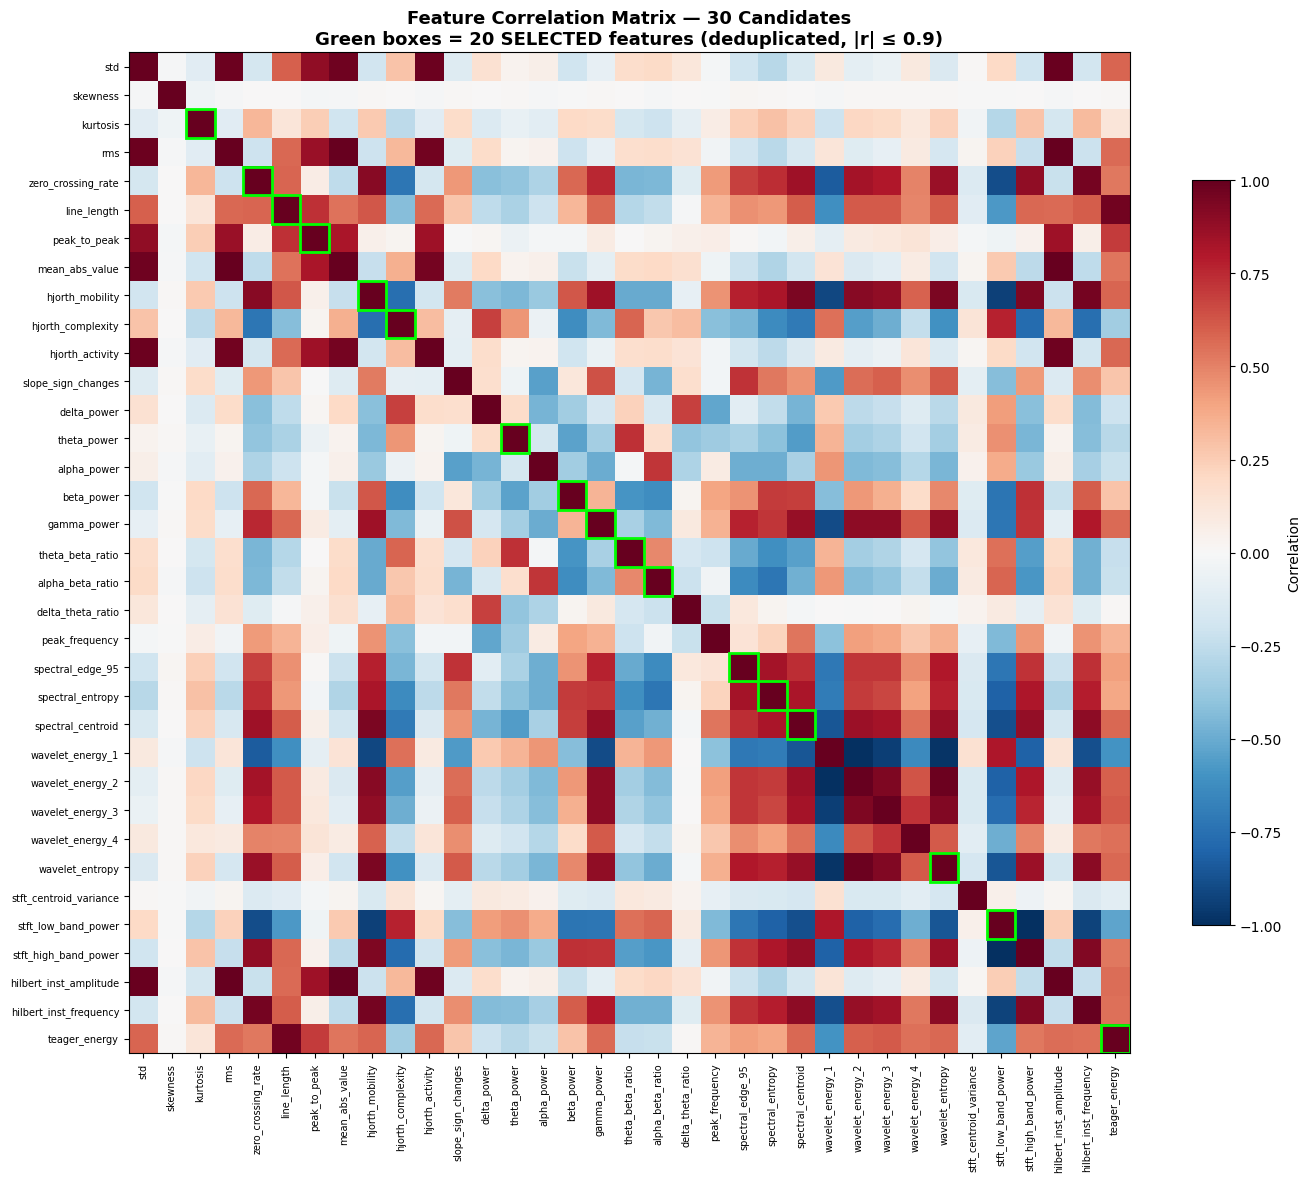

In [18]:
fflat_all = all_features.reshape(-1, N_CANDIDATES)
corr_matrix = np.corrcoef(flat_all.T)

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(N_CANDIDATES)); ax.set_xticklabels(ALL_CANDIDATE_NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(N_CANDIDATES)); ax.set_yticklabels(ALL_CANDIDATE_NAMES, fontsize=7)

for idx in selected_indices:
    ax.add_patch(plt.Rectangle((idx-0.5, idx-0.5), 1, 1, fill=False, edgecolor='lime', linewidth=2))

ax.set_title(f'Feature Correlation Matrix — 30 Candidates\nGreen boxes = 20 SELECTED features (deduplicated, |r| ≤ {CORR_DEDUP_THRESHOLD})',
            fontsize=13, fontweight='bold')
plt.colorbar(im, ax=ax, label='Correlation', shrink=0.7)
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'feature_correlation_dedup.png'), dpi=130, bbox_inches='tight')
plt.show()

# Save graph-structured .npz

In [19]:
final_features = all_features[:, :, :, selected_indices]   # (samples, T=6, N=60, F=20)

np.savez_compressed(str(FEAT_DIR / 'features_all.npz'),
                    node_features=final_features, y=y, subjects=subjects)
print(f'Saved graph-structured features: {final_features.shape}')

Saved graph-structured features: (3915, 6, 60, 17)


# Export combined labeled CSV

In [20]:
window_features = final_features.mean(axis=(1, 2))   # average across timesteps + channels -> (samples, 20)

df = pd.DataFrame(window_features, columns=selected_names)
df.insert(0, 'subject_id', subjects)
df.insert(1, 'window_index', np.arange(len(df)))
df.insert(2, 'label', y)   # 0 = Control, 1 = PD, exactly as instructed

csv_path = CSV_DIR / 'combined_features_labeled.csv'
df.to_csv(csv_path, index=False)

print(f'Saved combined labeled CSV: {df.shape[0]} rows × {df.shape[1]} columns → {csv_path.name}')
print(f'PD (label=1): {(df["label"]==1).sum()}   Control (label=0): {(df["label"]==0).sum()}')
df.head()

Saved combined labeled CSV: 3915 rows × 20 columns → combined_features_labeled.csv
PD (label=1): 2549   Control (label=0): 1366


,subject_id,window_index,label,hjorth_complexity,zero_crossing_rate,hjorth_mobility,line_length,kurtosis,peak_to_peak,beta_power,theta_beta_ratio,theta_power,spectral_entropy,alpha_beta_ratio,spectral_centroid,spectral_edge_95,gamma_power,stft_low_band_power,wavelet_entropy,teager_energy
0,1,0,1,1.998692,0.070413,0.234739,75.949303,-0.265220,4.214302,0.250789,0.988737,0.177552,0.570175,0.573544,16.963049,40.177776,0.244861,0.461451,0.605637,0.080407
1,1,1,1,1.738352,0.077232,0.248788,92.491409,-0.078675,4.961381,0.259587,0.911257,0.170824,0.574552,1.056863,16.962582,39.400002,0.222149,0.438505,0.673941,0.118503
2,1,2,1,1.643751,0.082615,0.265254,99.400497,-0.132304,4.930472,0.288534,0.766959,0.172634,0.585280,0.573794,18.312054,40.005554,0.254049,0.408721,0.733651,0.135736
3,1,3,1,1.692292,0.081096,0.259926,95.105103,-0.109309,4.875066,0.276820,0.860598,0.179702,0.580238,0.717442,17.658098,40.166668,0.235969,0.417830,0.709368,0.124145
4,1,4,1,1.681673,0.080127,0.258598,96.825264,-0.128091,4.998419,0.280986,0.807379,0.168857,0.580431,0.753474,17.974285,39.872223,0.243919,0.414533,0.686014,0.129601
